In [1]:
import pandas as pd
import numpy as np

In [2]:
load=pd.read_csv('clean_repair_cost_predict.csv')

In [3]:
load.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,67.2,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,67.2,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,67.2,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,67.2,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,67.2,40.0,9,0,0,0,0,0,0


In [4]:
load.drop(['UDI','Product ID'],axis=1,inplace=True)

In [5]:
load.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,67.2,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,67.2,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,67.2,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,67.2,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,67.2,40.0,9,0,0,0,0,0,0


In [6]:
load=pd.get_dummies(load,drop_first=True).astype(int)

In [7]:
load.tail()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Type_L,Type_M
9995,298,308,67,29,14,0,0,0,0,0,0,0,1
9996,298,308,67,31,17,0,0,0,0,0,0,0,0
9997,299,308,67,33,22,0,0,0,0,0,0,0,1
9998,299,308,67,48,25,0,0,0,0,0,0,0,0
9999,299,308,67,40,30,0,0,0,0,0,0,0,1


In [8]:
import seaborn as sns

In [9]:
import matplotlib.pyplot as plt

In [10]:
# sns.pairplot(load)

In [11]:
from scipy import stats

In [12]:
corr=load.corr()

In [13]:
corr.fillna(0)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Type_L,Type_M
Air temperature [K],1.000000,0.850477,0.0,-0.014056,0.011323,0.084178,0.008511,0.139943,0.002324,0.004478,0.015402,0.007784,0.008026
Process temperature [K],0.850477,1.000000,0.0,-0.015742,0.012060,0.032489,0.003528,0.054307,-0.001664,0.003965,0.022047,0.006077,0.005294
Rotational speed [rpm],0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Torque [Nm],-0.014056,-0.015742,0.0,1.000000,-0.002387,0.190636,-0.014649,0.143447,0.081182,0.181749,0.016409,0.001292,0.002001
Tool wear [min],0.011323,0.012060,0.0,-0.002387,1.000000,0.105448,0.115792,-0.001287,-0.009334,0.155894,0.011326,0.008232,-0.006976
Machine failure,0.084178,0.032489,0.0,0.190636,0.105448,1.000000,0.362904,0.575800,0.522812,0.531083,0.004516,0.035643,-0.022432
TWF,0.008511,0.003528,0.0,-0.014649,0.115792,0.362904,1.000000,-0.007332,0.008577,0.038243,0.030970,-0.007843,0.000690
HDF,0.139943,0.054307,0.0,0.143447,-0.001287,0.575800,-0.007332,1.000000,0.018443,0.046396,-0.004706,0.013402,-0.007095
PWF,0.002324,-0.001664,0.0,0.081182,-0.009334,0.522812,0.008577,0.018443,1.000000,0.115836,-0.004273,0.004209,0.005690
OSF,0.004478,0.003965,0.0,0.181749,0.155894,0.531083,0.038243,0.046396,0.115836,1.000000,-0.004341,0.058434,-0.045138


In [14]:
load.isna().sum()

Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
Type_L                     0
Type_M                     0
dtype: int64

In [15]:
corr.fillna(0)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Type_L,Type_M
Air temperature [K],1.000000,0.850477,0.0,-0.014056,0.011323,0.084178,0.008511,0.139943,0.002324,0.004478,0.015402,0.007784,0.008026
Process temperature [K],0.850477,1.000000,0.0,-0.015742,0.012060,0.032489,0.003528,0.054307,-0.001664,0.003965,0.022047,0.006077,0.005294
Rotational speed [rpm],0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Torque [Nm],-0.014056,-0.015742,0.0,1.000000,-0.002387,0.190636,-0.014649,0.143447,0.081182,0.181749,0.016409,0.001292,0.002001
Tool wear [min],0.011323,0.012060,0.0,-0.002387,1.000000,0.105448,0.115792,-0.001287,-0.009334,0.155894,0.011326,0.008232,-0.006976
Machine failure,0.084178,0.032489,0.0,0.190636,0.105448,1.000000,0.362904,0.575800,0.522812,0.531083,0.004516,0.035643,-0.022432
TWF,0.008511,0.003528,0.0,-0.014649,0.115792,0.362904,1.000000,-0.007332,0.008577,0.038243,0.030970,-0.007843,0.000690
HDF,0.139943,0.054307,0.0,0.143447,-0.001287,0.575800,-0.007332,1.000000,0.018443,0.046396,-0.004706,0.013402,-0.007095
PWF,0.002324,-0.001664,0.0,0.081182,-0.009334,0.522812,0.008577,0.018443,1.000000,0.115836,-0.004273,0.004209,0.005690
OSF,0.004478,0.003965,0.0,0.181749,0.155894,0.531083,0.038243,0.046396,0.115836,1.000000,-0.004341,0.058434,-0.045138


In [16]:
corrvalue=load['Air temperature [K]'].corr(load['Process temperature [K]'])

In [17]:
corrvalue

np.float64(0.850476714141275)

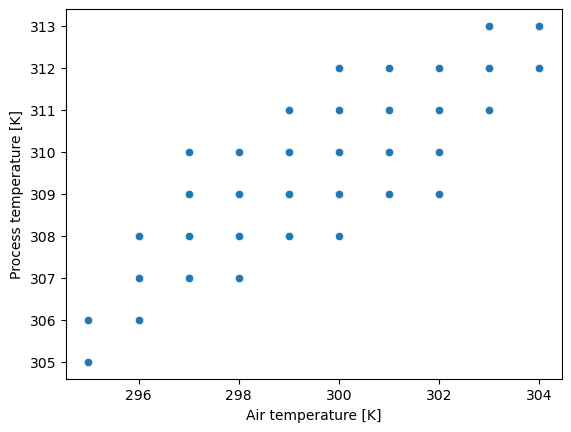

In [18]:
sns.scatterplot(data=load,x='Air temperature [K]',y='Process temperature [K]')
plt.show()

In [20]:
corrs = load["Rotational speed [rpm]"].corr(load["Torque [Nm]"])
print("Correlation:", corrs)


Correlation: nan


C:\Anaconda\Lib\site-packages\numpy\lib\_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Anaconda\Lib\site-packages\numpy\lib\_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [21]:
load.shape

(10000, 13)